Suhas Gullapelli - Face Recognition Model

Trains and evaluates face recognition on **Labeled Faces in the Wild** (LFW), a public dataset of news photos of public figures, and picks the settings used by the webcam app (`face_app.py`).

1. **Baseline: eigenfaces.** Raw pixels compressed with PCA, classified with an SVM (the classic approach).
2. **Deep embeddings.** A pretrained network (SFace) turns each aligned face into 128 numbers; photos of the same person land close together. Simple classifiers on top of those.
3. **How many photos to register?** Accuracy with 1 to 15 photos per person.
4. **Recognizing strangers as "Unknown".** Choosing the similarity threshold the app uses.

Face detection and embeddings come from `face_core.py`, the same code the app runs.

In [1]:
import json
import os
import time
import warnings

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import fetch_lfw_people

from face_core import FaceEngine, CONFIG_FILE

warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
RNG = np.random.default_rng(42)

## The data

Everyone in LFW with at least 20 photos, in color at full size (250x250). The first run downloads about 230 MB into `data/`.

In [2]:
lfw = fetch_lfw_people(min_faces_per_person=20, color=True, resize=1.0, slice_=None, data_home='data')
images = (lfw.images * 255).astype(np.uint8)            # RGB, 0-255
labels, names = lfw.target, lfw.target_names
print(f'{len(images)} photos of {len(names)} people')

counts = pd.Series(names[labels]).value_counts()
counts.describe().round(1)

3023 photos of 62 people


count     62.0
mean      48.8
std       71.1
min       20.0
25%       23.0
50%       31.0
75%       42.0
max      530.0
Name: count, dtype: float64

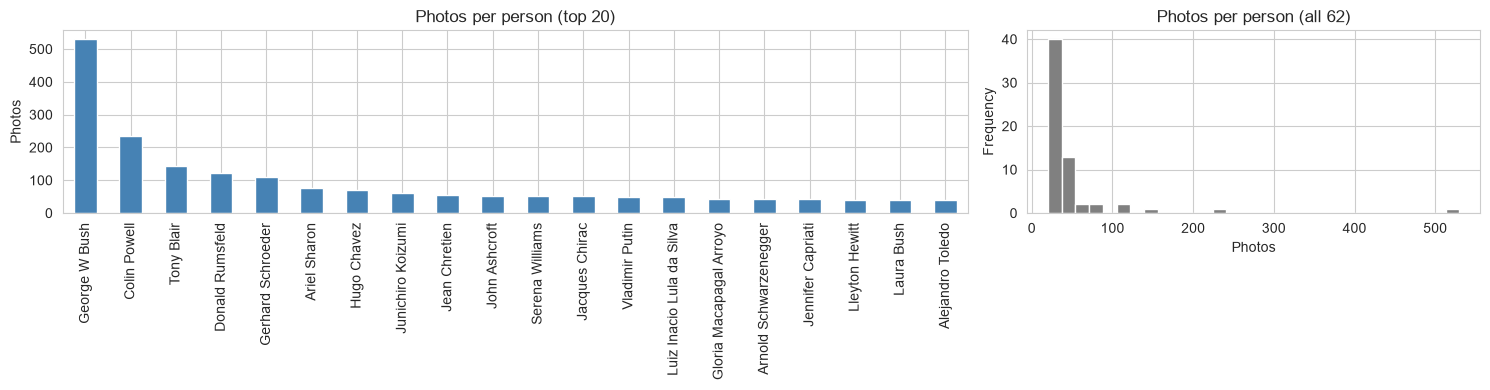

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4), gridspec_kw={'width_ratios': [2, 1]})
counts.head(20).plot(kind='bar', ax=axes[0], color='steelblue', title='Photos per person (top 20)')
axes[0].set_ylabel('Photos')
counts.plot(kind='hist', bins=30, ax=axes[1], color='gray', title='Photos per person (all 62)')
axes[1].set_xlabel('Photos')
plt.tight_layout()
plt.show()

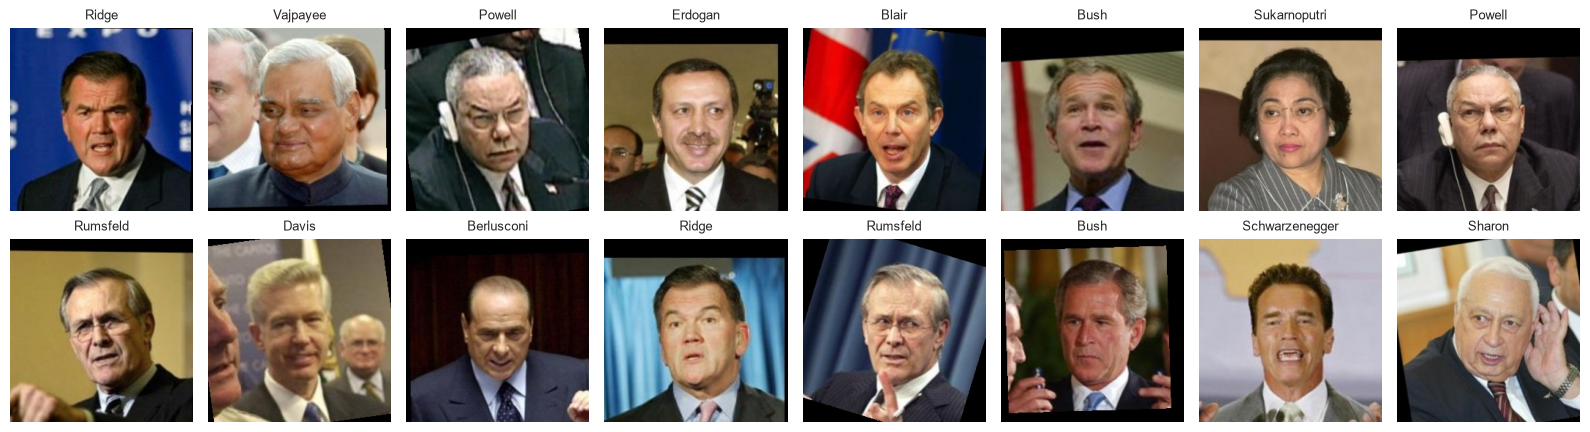

In [4]:
fig, axes = plt.subplots(2, 8, figsize=(16, 4.5))
for ax, i in zip(axes.flat, RNG.choice(len(images), 16, replace=False)):
    ax.imshow(images[i])
    ax.set_title(names[labels[i]].split()[-1], fontsize=9)
    ax.axis('off')
plt.tight_layout()
plt.show()

The classes are very unbalanced (George W. Bush alone has 530 photos), so besides accuracy we report **macro F1**, which weights every person equally.

## Embeddings

For each photo: YuNet finds the faces, the face nearest the center is kept (some photos show several people), it is aligned using the eye/nose/mouth landmarks, and SFace computes its embedding. Results are cached in `data/` so re-running is fast.

In [5]:
engine = FaceEngine(min_confidence=0.5)
cache = 'data/lfw_embeddings.npz'

if os.path.exists(cache):
    saved = np.load(cache)
    embeddings, found = saved['embeddings'], saved['found']
else:
    start = time.time()
    embeddings = np.zeros((len(images), 128), np.float32)
    found = np.zeros(len(images), bool)
    for i, rgb in enumerate(images):
        bgr = cv2.cvtColor(rgb, cv2.COLOR_RGB2BGR)
        faces = engine.detect(bgr)
        if len(faces):
            centers = faces[:, :2] + faces[:, 2:4] / 2
            face = faces[np.argmin(np.linalg.norm(centers - 125, axis=1))]
            embeddings[i] = engine.embed(bgr, face)
            found[i] = True
    np.savez(cache, embeddings=embeddings, found=found)
    print(f'{time.time() - start:.0f} seconds')

print(f'Face found in {found.sum()} of {len(found)} photos ({found.mean():.1%})')

Face found in 3023 of 3023 photos (100.0%)


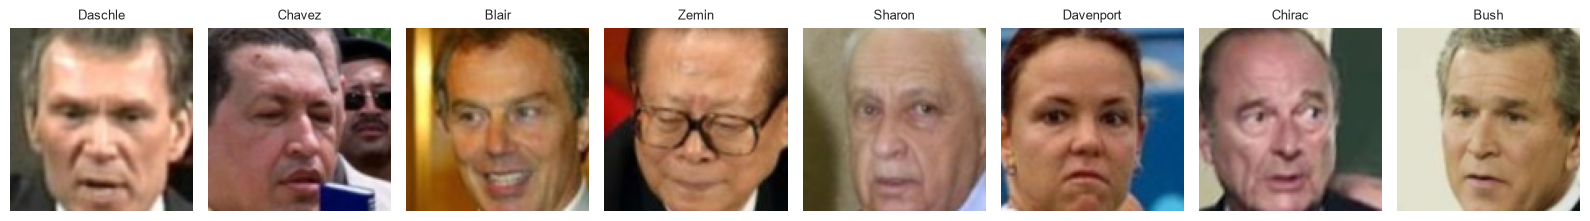

In [6]:
# What alignment produces: the 112x112 crops SFace sees
fig, axes = plt.subplots(1, 8, figsize=(16, 2.6))
for ax, i in zip(axes, RNG.choice(np.where(found)[0], 8, replace=False)):
    bgr = cv2.cvtColor(images[i], cv2.COLOR_RGB2BGR)
    faces = engine.detect(bgr)
    centers = faces[:, :2] + faces[:, 2:4] / 2
    aligned = engine.align(bgr, faces[np.argmin(np.linalg.norm(centers - 125, axis=1))])
    ax.imshow(cv2.cvtColor(aligned, cv2.COLOR_BGR2RGB))
    ax.set_title(names[labels[i]].split()[-1], fontsize=9)
    ax.axis('off')
plt.tight_layout()
plt.show()

## Training and test sets

Photos where no face was found are dropped (so both methods are judged on the same photos), then 75% of each person's photos go to training and 25% to testing.

In [7]:
from sklearn.model_selection import train_test_split

idx = np.where(found)[0]
train_idx, test_idx = train_test_split(idx, test_size=0.25, stratify=labels[idx], random_state=42)
y_train, y_test = labels[train_idx], labels[test_idx]
print(len(train_idx), 'training photos,', len(test_idx), 'test photos')

2267 training photos, 756 test photos


## 1. Baseline: eigenfaces

The classic method: crop the middle of the photo, shrink it to 62x47 grayscale, compress the 2,914 pixels into 150 "eigenfaces" with PCA, and classify with an SVM.

In [8]:
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, f1_score, classification_report

def pixels(i):
    gray = cv2.cvtColor(images[i][70:195, 78:172], cv2.COLOR_RGB2GRAY)
    return cv2.resize(gray, (47, 62), interpolation=cv2.INTER_AREA).flatten() / 255.0

X_pix = np.array([pixels(i) for i in range(len(images))])

eigenfaces = GridSearchCV(
    make_pipeline(PCA(n_components=150, whiten=True, random_state=42),
                  SVC(kernel='rbf', class_weight='balanced')),
    {'svc__C': [1, 10, 100], 'svc__gamma': ['scale', 0.001, 0.005]}, cv=3, n_jobs=-1)
eigenfaces.fit(X_pix[train_idx], y_train)
pred_eigen = eigenfaces.predict(X_pix[test_idx])
print('Best settings:', eigenfaces.best_params_)

results = [{'Method': 'Eigenfaces (PCA + SVM)', 'Accuracy': accuracy_score(y_test, pred_eigen),
            'Macro F1': f1_score(y_test, pred_eigen, average='macro')}]
pd.DataFrame(results).round(3)

Best settings: {'svc__C': 100, 'svc__gamma': 0.001}


,Method,Accuracy,Macro F1
0,Eigenfaces (PCA + SVM),0.61,0.532


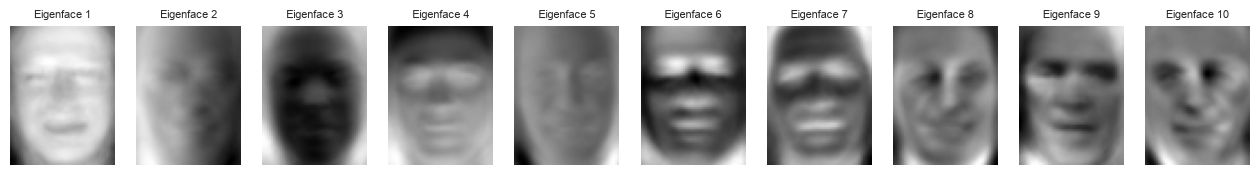

In [9]:
pca = eigenfaces.best_estimator_.named_steps['pca']
fig, axes = plt.subplots(1, 10, figsize=(16, 2.4))
for k, ax in enumerate(axes):
    ax.imshow(pca.components_[k].reshape(62, 47), cmap='gray')
    ax.set_title(f'Eigenface {k + 1}', fontsize=8)
    ax.axis('off')
plt.show()

## 2. Classifiers on the deep embeddings

- **Nearest neighbor**: the person whose single closest photo is most similar (cosine similarity). This is what the app does, since it needs no training: registering someone just stores embeddings.
- **Nearest centroid**: compare to each person's average embedding.
- **Logistic regression** and **linear SVM**: trained classifiers, for comparison.

In [10]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

E_train, E_test = embeddings[train_idx], embeddings[test_idx]

def nearest_neighbor(gallery, gallery_labels, probes):
    sims = probes @ gallery.T
    return gallery_labels[sims.argmax(axis=1)], sims.max(axis=1)

def nearest_centroid(gallery, gallery_labels, probes):
    people = np.unique(gallery_labels)
    centroids = np.array([gallery[gallery_labels == p].mean(axis=0) for p in people])
    centroids /= np.linalg.norm(centroids, axis=1, keepdims=True)
    return people[(probes @ centroids.T).argmax(axis=1)]

predictions = {
    'Nearest neighbor (embeddings)': nearest_neighbor(E_train, y_train, E_test)[0],
    'Nearest centroid (embeddings)': nearest_centroid(E_train, y_train, E_test),
    'Logistic regression (embeddings)': LogisticRegression(C=10, max_iter=2000, class_weight='balanced')
        .fit(E_train, y_train).predict(E_test),
    'Linear SVM (embeddings)': LinearSVC(C=1, class_weight='balanced').fit(E_train, y_train).predict(E_test),
}
for method, pred in predictions.items():
    results.append({'Method': method, 'Accuracy': accuracy_score(y_test, pred),
                    'Macro F1': f1_score(y_test, pred, average='macro')})

comparison = pd.DataFrame(results).set_index('Method')
comparison.round(3)

,Accuracy,Macro F1
Method,,
Eigenfaces (PCA + SVM),0.610,0.532
Nearest neighbor (embeddings),0.997,0.995
Nearest centroid (embeddings),0.997,0.995
Logistic regression (embeddings),0.997,0.995
Linear SVM (embeddings),0.997,0.995


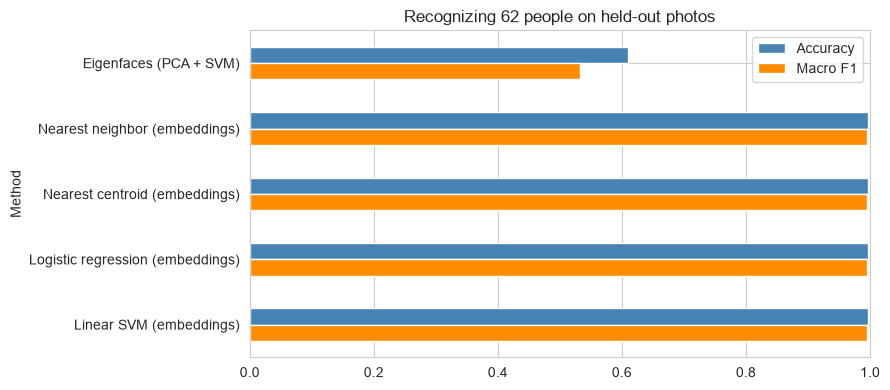

In [11]:
ax = comparison.plot(kind='barh', figsize=(9, 4), color=['steelblue', 'darkorange'])
ax.set_xlim(0, 1)
ax.set_title(f'Recognizing {len(names)} people on held-out photos')
ax.invert_yaxis()
plt.tight_layout()
plt.show()

**Why the embeddings are so much better, and why ~99.7% is optimistic.** Eigenfaces compare raw pixels, so lighting, pose and background swamp the differences between people. SFace was trained on millions of face photos to put the same person close together regardless of those, and alignment removes most pose differences. The embeddings are so well separated that even nearest neighbor needs no training.

The score is still optimistic for everyday use: LFW is the benchmark SFace was built to do well on (its published LFW accuracy is 99.6%), its training data likely includes many of these public figures, and LFW photos are well-lit press photos. Expect more mistakes with dim webcams, side views, or relatives who look alike.

### Where nearest neighbor goes wrong

In [12]:
pred_nn = predictions['Nearest neighbor (embeddings)']
report = pd.DataFrame(classification_report(y_test, pred_nn, target_names=names, output_dict=True,
                                            zero_division=0)).T.iloc[:len(names)]
print('People recognized least reliably:')
report.sort_values('f1-score').head(8).round(2)

People recognized least reliably:


,precision,recall,f1-score,support
Hamid Karzai,0.86,1.00,0.92,6.0
Mahmoud Abbas,1.00,0.86,0.92,7.0
Saddam Hussein,0.86,1.00,0.92,6.0
Recep Tayyip Erdogan,1.00,0.88,0.93,8.0
Angelina Jolie,1.00,1.00,1.00,5.0
Alejandro Toledo,1.00,1.00,1.00,10.0
Amelie Mauresmo,1.00,1.00,1.00,5.0
Alvaro Uribe,1.00,1.00,1.00,9.0


2 mistakes out of 756 test photos
Most common mix-ups (actual -> predicted):
Mahmoud Abbas -> Saddam Hussein         1
Recep Tayyip Erdogan -> Hamid Karzai    1


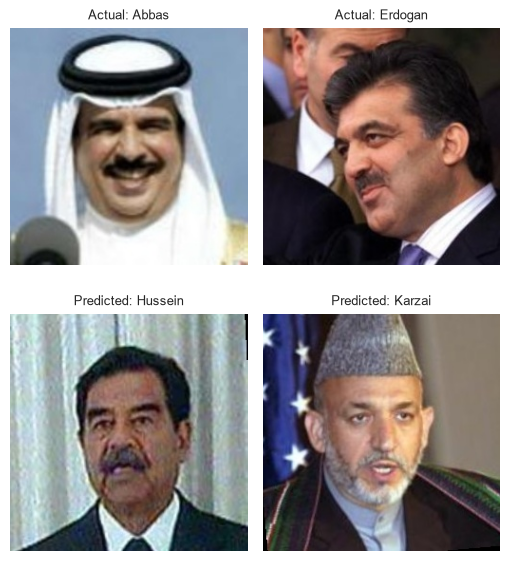

In [13]:
wrong = np.where(pred_nn != y_test)[0]
print(f'{len(wrong)} mistakes out of {len(y_test)} test photos')
pairs = pd.Series([f'{names[y_test[i]]} -> {names[pred_nn[i]]}' for i in wrong]).value_counts()
print('Most common mix-ups (actual -> predicted):')
print(pairs.head(8).to_string())

show = wrong[:6]
fig, axes = plt.subplots(2, len(show), figsize=(2.6 * len(show), 6))
for col, i in enumerate(show):
    example = train_idx[y_train == pred_nn[i]][0]
    axes[0, col].imshow(images[test_idx[i]])
    axes[0, col].set_title('Actual: ' + names[y_test[i]].split()[-1], fontsize=9)
    axes[1, col].imshow(images[example])
    axes[1, col].set_title('Predicted: ' + names[pred_nn[i]].split()[-1], fontsize=9)
for ax in axes.flat:
    ax.axis('off')
plt.tight_layout()
plt.show()

## 3. How many photos should you register?

In the app you register a person with a handful of photos. Here each person gets only *n* random training photos as their "registration", and every test photo is identified against that small gallery (5 random draws per *n*).

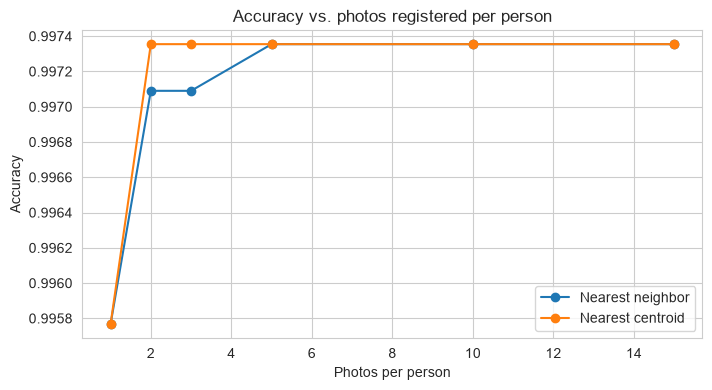

,Nearest neighbor,Nearest centroid
Photos per person,,
1,0.996,0.996
2,0.997,0.997
3,0.997,0.997
5,0.997,0.997
10,0.997,0.997
15,0.997,0.997


In [14]:
shots = [1, 2, 3, 5, 10, 15]
rows = []
for n in shots:
    for draw in range(5):
        gallery = np.concatenate([RNG.choice(np.where(y_train == p)[0], n, replace=False)
                                  for p in np.unique(y_train) if (y_train == p).sum() >= n])
        keep = np.isin(y_test, y_train[gallery])
        nn = nearest_neighbor(E_train[gallery], y_train[gallery], E_test[keep])[0]
        nc = nearest_centroid(E_train[gallery], y_train[gallery], E_test[keep])
        rows.append({'Photos per person': n, 'Nearest neighbor': accuracy_score(y_test[keep], nn),
                     'Nearest centroid': accuracy_score(y_test[keep], nc)})
few_shot = pd.DataFrame(rows).groupby('Photos per person').mean()
ax = few_shot.plot(marker='o', figsize=(8, 4), title='Accuracy vs. photos registered per person')
ax.set_ylabel('Accuracy')
plt.show()
few_shot.round(3)

## 4. Telling strangers apart: the "Unknown" threshold

The app should say **Unknown** for people it hasn't registered instead of guessing the closest match. To choose the cutoff, 42 people are "registered" with 10 photos each and the other 20 act as strangers. For every remaining photo we take the best similarity to anyone registered:
- **Registered people** should score above the threshold *and* match the right name.
- **Strangers** should score below it.

Repeated over 10 random splits of who is registered.

In [15]:
genuine, genuine_correct, impostor = [], [], []
people = np.unique(labels[idx])
for split in range(10):
    known = RNG.choice(people, 42, replace=False)
    gallery, probes = [], []
    for p in known:
        photos = RNG.permutation(idx[labels[idx] == p])
        gallery += list(photos[:10])
        probes += list(photos[10:])
    gallery, probes = np.array(gallery), np.array(probes)
    strangers = idx[~np.isin(labels[idx], known)]

    pred, score = nearest_neighbor(embeddings[gallery], labels[gallery], embeddings[probes])
    genuine += list(score)
    genuine_correct += list(pred == labels[probes])
    impostor += list(nearest_neighbor(embeddings[gallery], labels[gallery], embeddings[strangers])[1])

genuine, genuine_correct, impostor = map(np.array, (genuine, genuine_correct, impostor))
print(f'{len(genuine):,} photos of registered people, {len(impostor):,} photos of strangers')

16,249 photos of registered people, 9,781 photos of strangers


In [16]:
thresholds = np.round(np.arange(0.15, 0.71, 0.01), 2)
curve = pd.DataFrame({
    'Threshold': thresholds,
    'Registered people named correctly': [((genuine >= t) & genuine_correct).mean() for t in thresholds],
    'Strangers wrongly given a name': [(impostor >= t).mean() for t in thresholds],
}).set_index('Threshold')

# Lowest threshold that names at most 1% of strangers
threshold = float(curve.index[curve['Strangers wrongly given a name'] <= 0.01][0])
chosen = curve.loc[threshold]
print(f'Chosen threshold: {threshold}')
print(f"  Registered people named correctly: {chosen['Registered people named correctly']:.1%}")
print(f"  Strangers wrongly given a name:    {chosen['Strangers wrongly given a name']:.1%}")
curve.loc[[0.25, 0.3, 0.35, threshold, 0.45, 0.5]].round(3)

Chosen threshold: 0.46
  Registered people named correctly: 99.9%
  Strangers wrongly given a name:    0.8%


,Registered people named correctly,Strangers wrongly given a name
Threshold,,
0.25,1.000,0.992
0.30,1.000,0.862
0.35,1.000,0.458
0.46,0.999,0.008
0.45,0.999,0.013
0.50,0.998,0.000


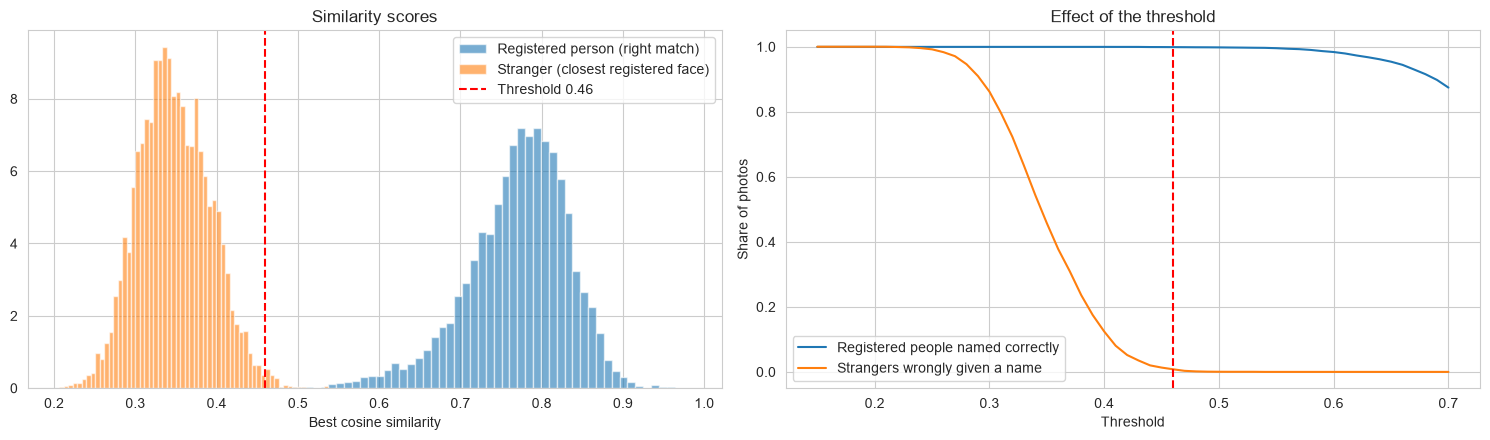

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
axes[0].hist(genuine[genuine_correct], bins=60, alpha=0.6, density=True, label='Registered person (right match)')
axes[0].hist(impostor, bins=60, alpha=0.6, density=True, label='Stranger (closest registered face)')
axes[0].axvline(threshold, color='red', linestyle='--', label=f'Threshold {threshold}')
axes[0].set_xlabel('Best cosine similarity')
axes[0].set_title('Similarity scores')
axes[0].legend()

curve.plot(ax=axes[1], title='Effect of the threshold')
axes[1].axvline(threshold, color='red', linestyle='--')
axes[1].set_ylabel('Share of photos')
plt.tight_layout()
plt.show()

## Settings for the app

`face_app.py` reads this file. LFW is news photography; webcam images differ (lighting, camera quality), so the app also takes `--threshold` to adjust it.

In [18]:
config = {
    'threshold': threshold,
    'registered_named_correctly': round(float(chosen['Registered people named correctly']), 3),
    'strangers_given_a_name': round(float(chosen['Strangers wrongly given a name']), 3),
    'photos_per_person_tested': 10,
    'source': 'face_recognition_model.ipynb (LFW, 42 registered / 20 strangers, 10 splits)',
}
with open(CONFIG_FILE, 'w') as f:
    json.dump(config, f, indent=2)
config

{'threshold': 0.46,
 'registered_named_correctly': 0.999,
 'strangers_given_a_name': 0.008,
 'photos_per_person_tested': 10,
 'source': 'face_recognition_model.ipynb (LFW, 42 registered / 20 strangers, 10 splits)'}